# The Dying ReLU Problem

- Relu is the best choice of activation function for hidden layers in deep neural networks. However, it has a big problem called the Dying ReLU problem. (It was not discussed in the previous lesson)

- When using ReLU, some neurons will always output 0. These neurons are called dead neurons.

- Once a neuron is dead, it will never activate on any datapoint again. So it will be forever dead. and always give 0 as output.

- So if 50% of the neurons in a layer are dead, then the effective number of neurons in that layer is halved. This will reduce the capacity of the model and it will not be able to learn complex patterns in the data.

- The Dying ReLU problem is caused by large gradients flowing through a ReLU neuron. This can cause the weights to update in such a way that the neuron will never activate on any datapoint again.

- Worst case scenario is that all the neurons in a layer are dead. Then the model will not be able to learn anything at all.



# Why does the Dying ReLU problem happen?
- Let's take the below NN as example to understand why the Dying ReLU problem happens.
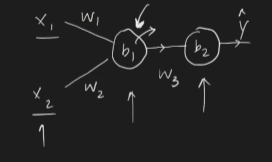

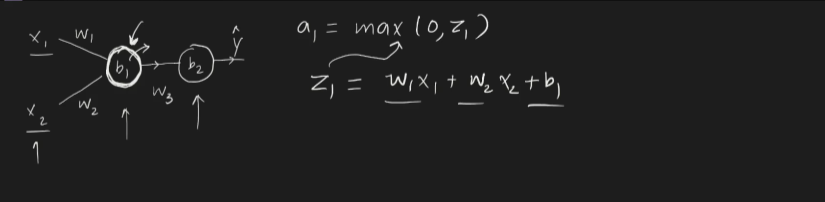

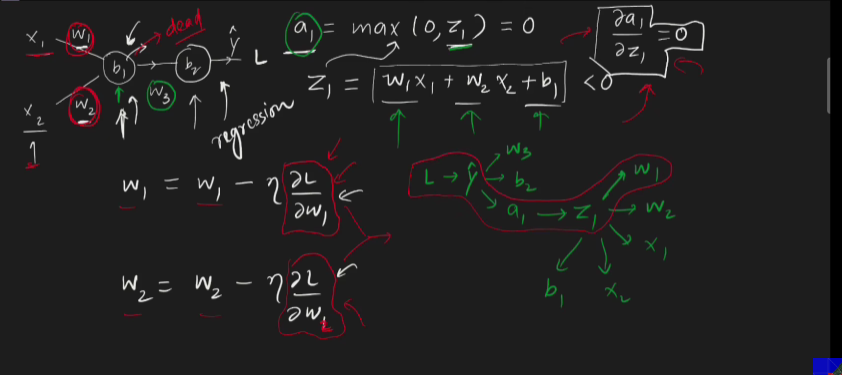

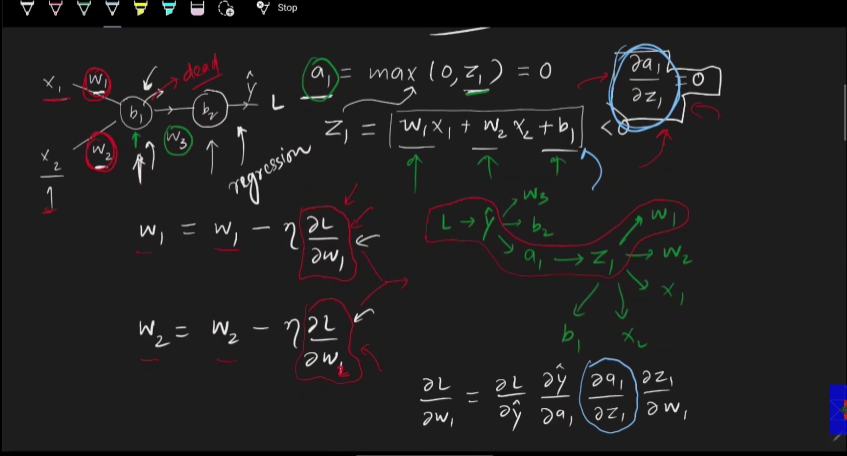

- So you can see once input $z_1$ is negative, the output of the ReLU neuron $a_1$ will be 0. This means that the gradient flowing through this neuron will also be 0. So the weights of this neuron will not update and it will never activate on any datapoint again. This is how a neuron dies.

- So, everything depends on the input $z_1$. If $z_1$ is negative, then the neuron will die. If $z_1$ is positive, then the neuron will be alive.

### Reasons for $z_1$ being negative


$$ z_1 = w_1 x_1 + w_2 x_2 + b$$

1. **High learning rate**: If the learning rate is too high, then the 2nd term in the update equation will be very large. This can cause the weights to be negative and $z_1$ will be negative. So the neuron will die.

$$ w_i = w_i - \eta \frac{\partial L}{\partial w_i}$$


2. **Highly negative bias**: If the bias is highly negative, then $z_1$ will be negative and the neuron will die.
    - Bias can be negative in two ways:
        1. If the bias is initialized to a negative value, then the neuron will die.
        2. If the bias is updated to a highly negative value because of high learning rates during training, then the neuron will die.


## Why once a neuron dies, it will never come back to life?

- When neuron dies, either its weights are negative or its bias is highly negative. And inputs $X_i$ are normaized to be between 0 and 1. So $z_1$ will always be negative and the neuron will never activate on any datapoint again. So it will be forever dead.

# Solutions to the Dying ReLU problem

1. To set a lower learning rate. This will prevent the weights from being updated to negative values and the neuron will not die.

2. Set a positive bias. This will prevent the neuron from dying because $z_1$ will always be positive. (**b = 0.01** is a good choice)

3. Use Leaky ReLU or other alternative for ReLU instead of ReLU. Leaky ReLU has a small slope for negative inputs. So even if $z_1$ is negative, the output of the neuron will not be 0. This will prevent the neuron from dying.

# Variants of ReLU

- There are 2 types of variants of Relu
    1. Linear variants of ReLU: Formed by making linear transformations of ReLU. 
        - Leaky ReLU: $f(x) = max(0.01x,x)$
        - Parametric ReLU: $f(x) = max(ax,x)$ where a is a learnable parameter
    2. Non-linear variants of ReLU: Formed by making non-linear transformations of ReLU.
        - Exponential Linear Unit (ELU): $f(x) = x$ if $x>0$ else $f(x) = \alpha(e^x - 1)$ where $\alpha$ is a hyperparameter.
        - Scaled Exponential Linear Unit (SELU): $f(x) = \lambda x$ if $x>0$ else $f(x) = \lambda \alpha(e^x - 1)$ where $\lambda$ and $\alpha$ are hyperparameters.

## 1. Leaky ReLU

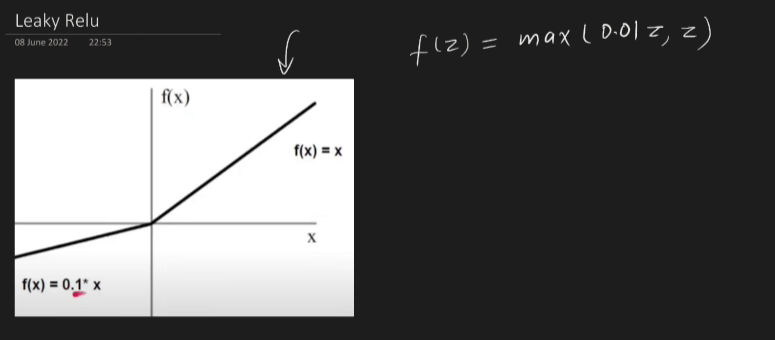

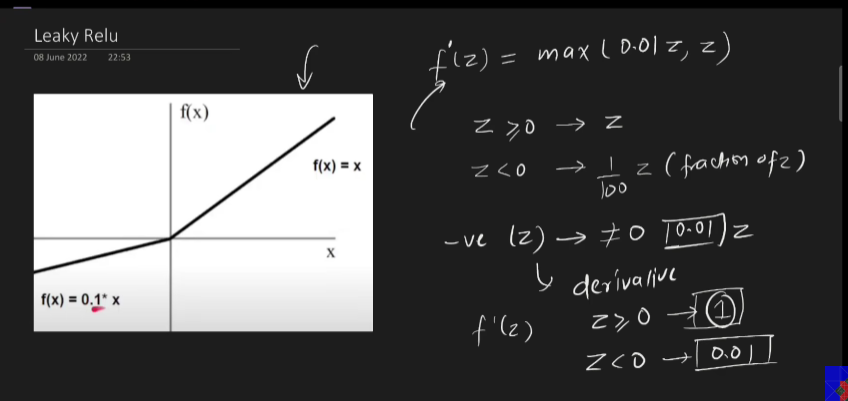

- Leaky ReLU has a small slope for negative inputs. So even if $z_1$ is negative, the output of the neuron will not be 0. This will prevent the neuron from dying.

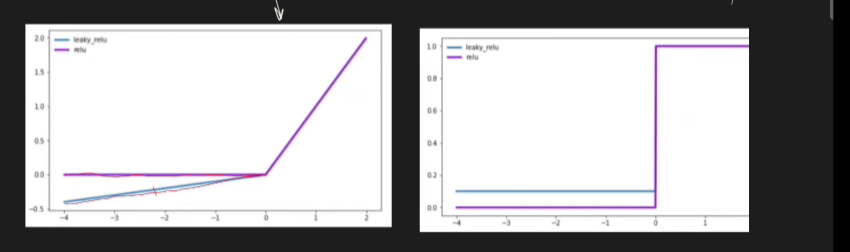

### Advantages of Leaky ReLU

1. Non-saturating: Leaky ReLU is non-saturating. So it does not have the vanishing gradient problem. This means that the gradients will not be 0 and the weights will keep updating. So the model will keep learning.

2. Easy to compute: Leaky ReLU is easy to compute. It is just a linear function. So it is computationally efficient.

3. No dying ReLU problem: Leaky ReLU does not have the dying ReLU problem. So all the neurons will be alive and the model will have more capacity to learn complex patterns in the data.

4. Close to zero-centered: Not exactly zero-centered, but close to zero-centered. This means that the mean of the output of the neuron will be close to 0. This will help in faster convergence of the model.

## 2. Parametric ReLU

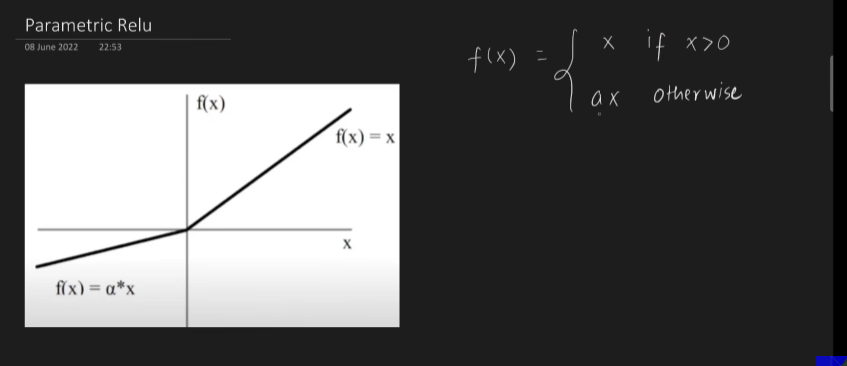

- Parametric ReLU is similar to Leaky ReLU, but the slope for negative inputs is a learnable parameter. This means that the model can learn the best slope for negative inputs during training of the neural network according to the data.

- Learnable slope is the only advantage of Parametric ReLU over Leaky ReLU. Else everything else is same as Leaky ReLU.

## 3. Exponential Linear Unit (ELU)

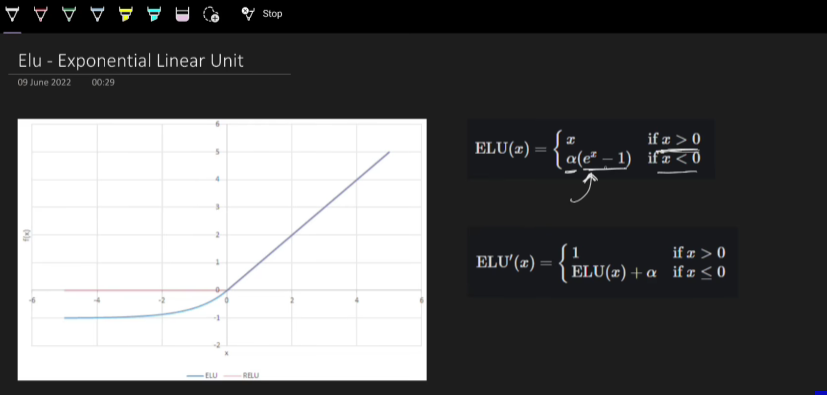

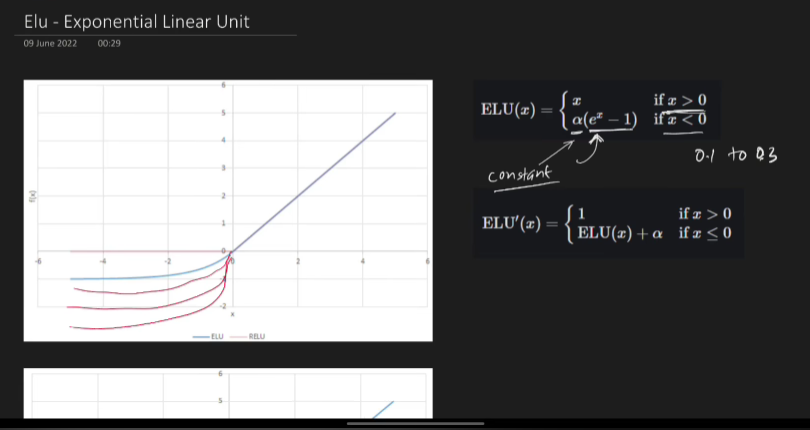

- $\alpha$ is a hyperparameter that controls the value of the exponential term for negative inputs. It is usually between 0.1 to 0.3

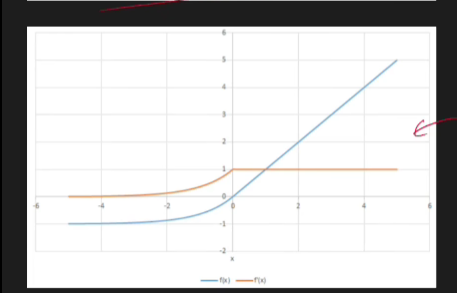

### Advantages of ELU

1. Closer to zero-centered: ELU is closer to zero-centered than Leaky ReLU and Parametric ReLU. This means that the mean of the output of the neuron will be closer to 0. This will help in faster convergence of the model.

2. Better generalization: ELU has better generalization than Leaky ReLU and Parametric ReLU. This means that the model will perform better on unseen data.

3. No dying ReLU problem: ELU does not have the dying ReLU problem. So all the neurons will be alive and the model will have more capacity to learn complex patterns in the data.

4. Always continous and differentiable: ELU is always continuous and differentiable. 

### Disadvantages of ELU

1. Computationally expensive: ELU is computationally expensive than Leaky ReLU and Parametric ReLU. This is because of the exponential term in the function.

## 4. Scaled Exponential Linear Unit (SELU)

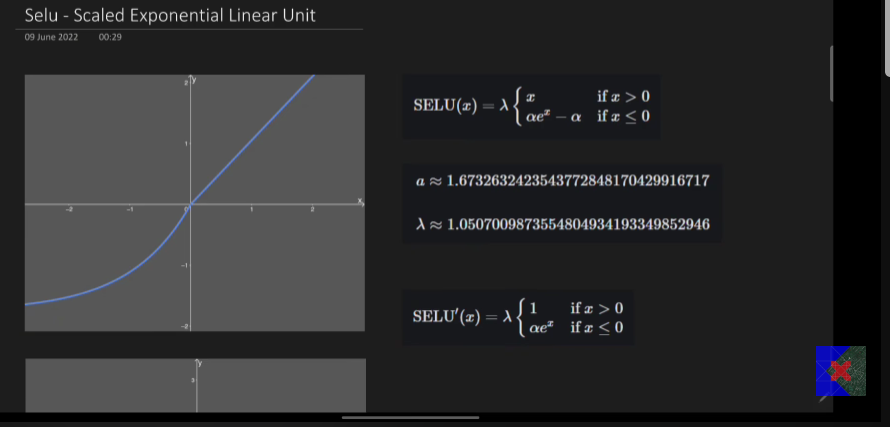

- The SELU activation function is a scaled version of the ELU activation function. It has two hyperparameters, $\lambda$ and $\alpha$, which are used to scale the output of the ELU function. Both are usually set to 1.0507 and 1.6733 respectively. And are not learnable parameters. So they are fixed during training of the neural network.

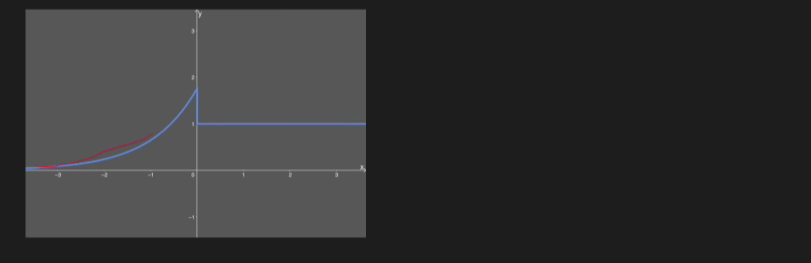

### Advantages of SELU

- Biggest advantage of SELU is that it has **self-normalizing property**. This means that the output of the neuron will have mean 0 and variance 1. This will help in faster convergence of the model.